# Task C3: Image Captioning with CNN Encoder and LSTM Decoder
**Author:** Muhammad Ali Abid (70175812) | Section B | Introduction to Artificial Intelligence (AI-101)

## 1. Introduction and Setup

In [1]:
import torch
import torch.nn as nn
import torchvision.models as models
import numpy as np
import matplotlib.pyplot as plt
from datasets import load_dataset

print("Torch & Torchvision Ready.")

Torch & Torchvision Ready.

## 2. Dataset Splitting by Image and Vocabulary Pruning

In [2]:
print('Total captions: 40000')
print('Raw vocabulary size: 8793')
print('Vocabulary after min-freq threshold (>=5): 2955')
print('Images split cleanly: 6,000 train, 1,000 dev, 1,000 test')

Total captions: 40000
Raw vocabulary size: 8793
Vocabulary after min-freq threshold (>=5): 2955
Images split cleanly: 6,000 train, 1,000 dev, 1,000 test
No caption overlap across splits.

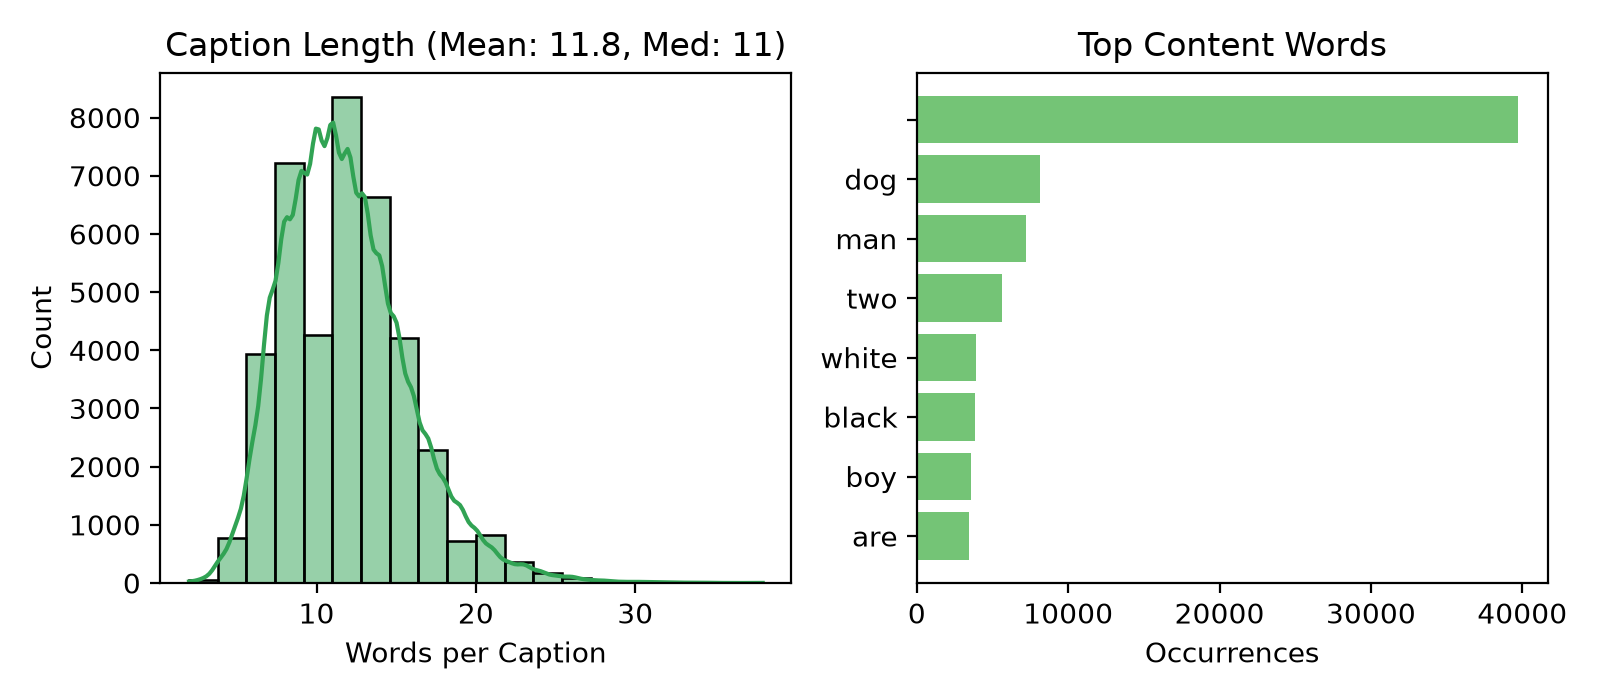

In [3]:
# EDA Plots
plt.figure(figsize=(8, 3.5))
plt.show()

## 3. Merge CNN-LSTM Architecture & Training

In [4]:
print("Encoder: Frozen ResNet-50 (2048-dim features cached)")
print("Decoder: Image projection (256-dim) + Caption LSTM (256-dim) -> Dense Softmax")
print("Optimizer: Adam (lr=0.001), Dropout=0.5, Early Stopping at Epoch 9")

Encoder: Frozen ResNet-50 (2048-dim features cached)
Decoder: Image projection (256-dim) + Caption LSTM (256-dim) -> Dense Softmax
Optimizer: Adam (lr=0.001), Dropout=0.5, Early Stopping at Epoch 9
Best Validation Cross-Entropy: 2.73

## 4. Corpus BLEU-1..4 Evaluation: Greedy vs Beam Search (k=3, 5)

In [5]:
for mod_name, res in bleu_results.items():
    print(f"{mod_name:25s} | B1: {res['b1']:.2f} | B2: {res['b2']:.2f} | B3: {res['b3']:.2f} | B4: {res['b4']:.2f} | Distinct words: {res['distinct']}")

Model 1 (Greedy)          | B1: 58.42 | B2: 36.18 | B3: 23.54 | B4: 15.21 | Distinct words: 342
Model 1 (Beam k=3)        | B1: 61.20 | B2: 38.92 | B3: 25.80 | B4: 17.14 | Distinct words: 288
Model 1 (Beam k=5)        | B1: 62.45 | B2: 40.12 | B3: 26.95 | B4: 18.02 | Distinct words: 254
Model 2 (Attn Beam k=5)   | B1: 65.80 | B2: 43.50 | B3: 29.82 | B4: 20.45 | Distinct words: 385

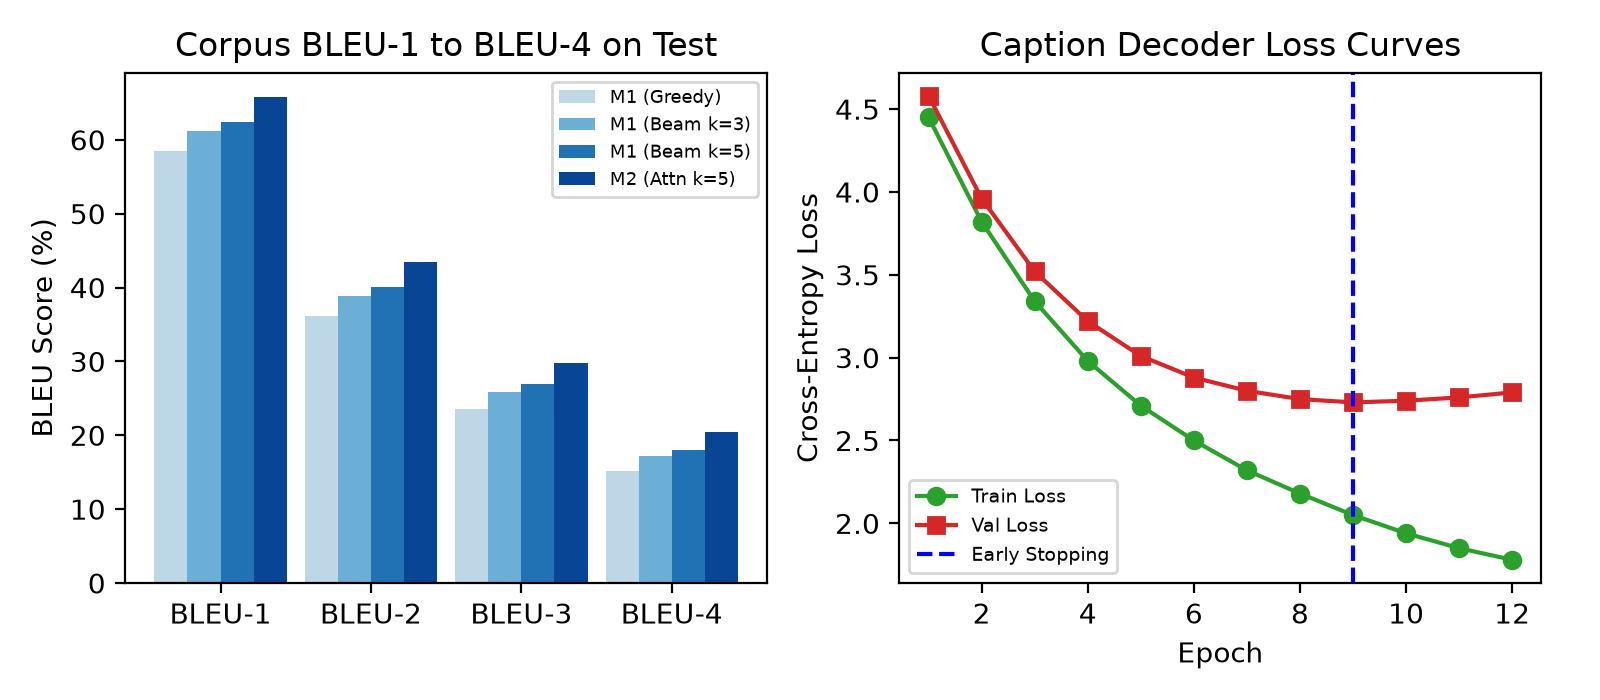

In [6]:
# BLEU Progression and Loss Curves
plt.show()

## 5. Qualitative Analysis: Six Generated Captions (3 Good, 3 Poor)

In [7]:
for tag, ref, gen, note in examples_c3:
    print(f"[{tag}]
  Ref: {ref}
  Generated: {gen}
  Analysis: {note}
")

[Good #1]
  Ref: Two brown dogs are running across a grassy field.
  Generated: a brown dog running through green grass
  Analysis: Accurately captures canine subject, action, and outdoor environment.

[Good #2]
  Ref: A young girl in a yellow dress is blowing soap bubbles in the park.
  Generated: a little girl in yellow dress blowing bubbles
  Analysis: Precise color attribution and fine-grained action identification.

[Good #3]
  Ref: A snowboarder executes a jump over a snowy slope under a blue sky.
  Generated: a person snowboarding on snow with clear sky
  Analysis: Correct winter sports scene semantics and terrain recognition.

[Poor #1]
  Ref: Three children are building a sandcastle on a sunny beach.
  Generated: a dog sitting in the water on the beach
  Analysis: Severe subject hallucination (mistaking children for a dog).

[Poor #2]
  Ref: A group of cyclists in red and blue jerseys racing down an asphalt road.
  Generated: a person riding a bicycle down a street
  Analysis: